# 🚢 Titanic Survival Prediction

A beginner-friendly, end-to-end machine learning project.

## 1. Project overview

**Goal.** Build a model that estimates whether a passenger on the Titanic survived, using only information that would be known *about the passenger* (ticket class, sex, age, family aboard, fare, and port of embarkation).

**Target.** The column `survived` is a **binary target**:

| Value | Meaning |
|---|---|
| `0` | The passenger did **not** survive |
| `1` | The passenger **survived** |

This makes the task a **binary classification** problem.

### Workflow

1. Load and validate the data
2. Explore the data (EDA)
3. Avoid data leakage and choose features
4. Engineer new features
5. Split the data, then build preprocessing pipelines
6. Compare a baseline and several models
7. Interpret the selected model
8. Fit a final model and make an example prediction
9. Summarize results and limitations

### Questions this analysis investigates

- How balanced are the two outcomes?
- How do sex, passenger class, age, fare, port of embarkation, and family size relate to survival?
- Which columns in this dataset must be **excluded** because they would leak the answer?
- Does a simple engineered feature (`family_size`) help?
- How much better is a real model than a "no-skill" baseline?
- Which features does the selected model rely on, and what can (and cannot) we conclude from that?

> **Important:** everything below shows *statistical associations* in one historical dataset. It does not prove what caused any individual outcome.

## 2. Imports and notebook setup

We import the libraries once, set a **random seed** (so results are reproducible), and choose a clean chart style.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    make_scorer, ConfusionMatrixDisplay, RocCurveDisplay,
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
RANDOM_STATE = 42          # one seed used everywhere for reproducibility
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

# Consistent colors for the two outcomes in every chart
OUTCOME_LABELS = {0: "Did not survive", 1: "Survived"}
OUTCOME_COLORS = {"Did not survive": "#E4572E", "Survived": "#2E86AB"}
BAR_COLOR = "#2E86AB"

pd.set_option("display.max_columns", 30)
print("Setup complete. Random seed:", RANDOM_STATE)

Setup complete. Random seed: 42


## 3. Load and validate the data

The notebook looks for `Titanic.csv` in the current folder first (the normal case when the notebook is opened from the project folder), then one folder up.

In [ ]:
CANDIDATE_PATHS = [Path("Titanic.csv"), Path("../Titanic.csv")]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Titanic.csv was not found. Open this notebook from the project folder "
        "(the folder that contains Titanic.csv)."
    )

PROJECT_DIR = DATA_PATH.resolve().parent   # used later to save the model file
raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH.resolve())
print("Shape (rows, columns):", raw.shape)

Loaded: /home/claude/work/Titanic.csv
Shape (rows, columns): (891, 16)


### 3.1 First look: sample rows, column names, and data types

In [ ]:
display(raw.head())
print("Columns:", list(raw.columns))

,Unnamed: 0,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Columns: ['Unnamed: 0', 'survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [ ]:
display(raw.dtypes.rename("data type").to_frame())

,data type
Unnamed: 0,int64
survived,int64
pclass,int64
sex,str
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,str
class,str


### 3.2 The unnamed index column

When a DataFrame is saved with `to_csv()` *without* `index=False`, pandas writes the row numbers as an extra first column. When the file is read again, that column appears as `Unnamed: 0`. Let's confirm that is what happened here.

In [ ]:
index_columns = [c for c in raw.columns if str(c).startswith("Unnamed")]
print("Unnamed columns found:", index_columns)

for col in index_columns:
    is_row_number = bool((raw[col].to_numpy() == np.arange(len(raw))).all())
    print(f"'{col}' is just the row number 0..{len(raw) - 1}: {is_row_number}")

# Remove it: a row number carries no information about the passenger.
df = raw.drop(columns=index_columns).copy()
print("Columns after removing the index column:", list(df.columns))

Unnamed columns found: ['Unnamed: 0']
'Unnamed: 0' is just the row number 0..890: True
Columns after removing the index column: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


The row number is an **identifier, not a passenger characteristic**, so it is dropped and never used as a model feature.

### 3.3 Descriptive statistics, duplicates, and missing values

In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [ ]:
display(df.describe(include=["object", "string", "bool"]).T)

,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
adult_male,891,2,True,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549
alone,891,2,True,537


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1),
})
display(missing.sort_values("missing_count", ascending=False))

Duplicate rows: 107


,missing_count,missing_percent
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2
sex,0,0.0
pclass,0,0.0
survived,0,0.0
fare,0,0.0
parch,0,0.0
sibsp,0,0.0


### 3.4 Check that the required columns exist

We never *assume* a column exists. This cell stops with a clear message if something is missing, and also confirms the target only contains `0` and `1`.

In [ ]:
TARGET = "survived"
MODEL_COLUMNS_NEEDED = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]

missing_cols = [c for c in [TARGET] + MODEL_COLUMNS_NEEDED if c not in df.columns]
assert not missing_cols, f"Missing required columns: {missing_cols}"
assert set(df[TARGET].unique()) <= {0, 1}, "Target must only contain 0 and 1"

# Columns commonly seen in other Titanic files that this file may not have
common_kaggle_columns = ["Name", "Ticket", "Cabin", "PassengerId"]
print("Required columns present: OK")
print("Common Kaggle columns present in this file:",
      [c for c in common_kaggle_columns if c in df.columns] or "none (we will not use them)")

Required columns present: OK
Common Kaggle columns present in this file: none (we will not use them)


**A note on duplicate rows.** The duplicate count above counts rows whose values are identical in *every* remaining column. This file has no passenger ID or name, so we cannot tell whether such rows are accidental copies or different people who simply share the same recorded values (common for passengers travelling alone in the same class who paid the same fare). Because we cannot prove they are errors, **we keep them** rather than silently deleting data.

**What we learned about the data quality**

- The index column was removed.
- Some columns have missing values (see the table above); we will visualize them in the EDA and handle them inside the model pipeline.
- There are no `Name`, `Ticket`, or `Cabin` columns, so the analysis is built only on the columns that are actually present.

## 4. Exploratory Data Analysis (EDA)

EDA means *looking at the data before modeling*. Each chart below is followed by what it shows.
We first add a readable text label for the target to make legends clearer. This is only used for plotting.

In [ ]:
eda = df.copy()
eda["outcome"] = eda[TARGET].map(OUTCOME_LABELS)
overall_rate = eda[TARGET].mean()

def plot_survival_rate(data, column, ax, title, xlabel, order=None):
    """Bar chart of the survival rate per group. Each bar also shows the group size (n)."""
    summary = data.groupby(column, observed=True)[TARGET].agg(passengers="size", survival_rate="mean")
    if order is not None:
        summary = summary.reindex(order)
    positions = range(len(summary))
    ax.bar(positions, summary["survival_rate"], color=BAR_COLOR)
    for i, (rate, n) in enumerate(zip(summary["survival_rate"], summary["passengers"])):
        ax.text(i, rate + 0.02, f"{rate:.0%}\n(n={n})", ha="center", va="bottom", fontsize=9)
    ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1, label="Overall survival rate")
    ax.set_xticks(list(positions))
    ax.set_xticklabels([str(x) for x in summary.index])
    ax.set_ylim(0, 1.2)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Survival rate")
    ax.legend(loc="upper right", fontsize=8)
    return summary

### 4.1 Target classes: how many passengers survived?

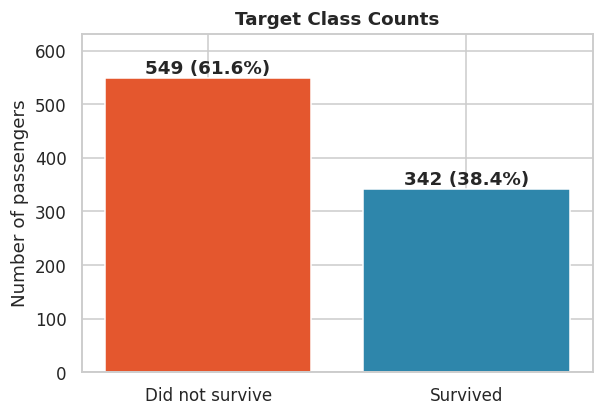

In [ ]:
counts = eda["outcome"].value_counts().reindex(list(OUTCOME_LABELS.values()))
percents = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=[OUTCOME_COLORS[c] for c in counts.index])
for bar, count, pct in zip(bars, counts.values, percents.values):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 8, f"{count} ({pct:.1f}%)", ha="center", fontweight="bold")
ax.set_title("Target Class Counts")
ax.set_ylabel("Number of passengers")
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

**What this shows:** the number and share of passengers in each outcome. The classes are somewhat imbalanced, so a model that always predicts the larger class would already get a decent accuracy. That is why we include a **baseline** later and look at more metrics than accuracy alone.

### 4.2 Survival by sex and passenger class

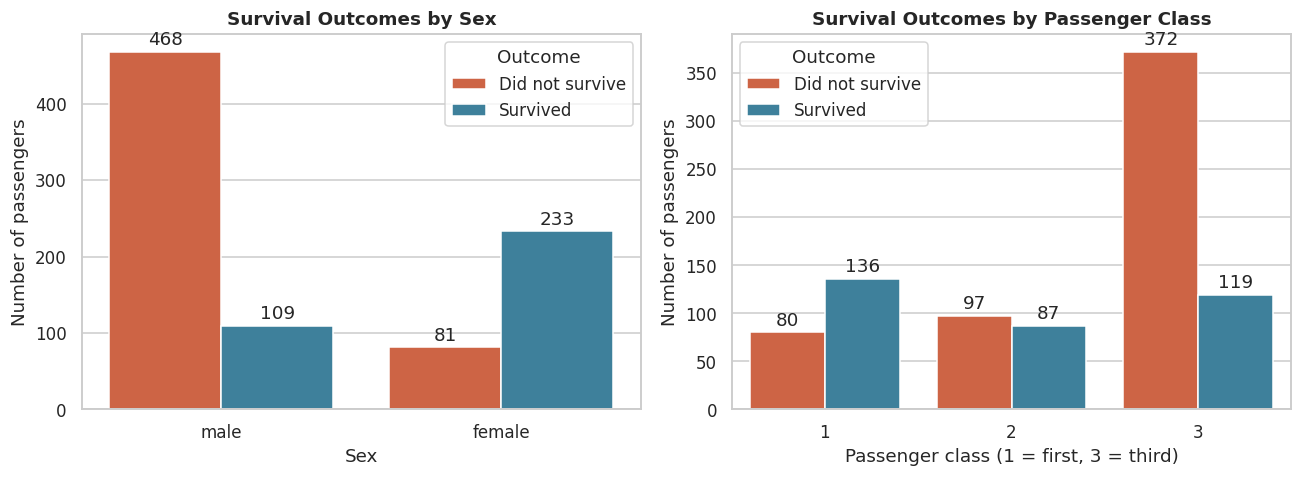

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(data=eda, x="sex", hue="outcome", hue_order=list(OUTCOME_LABELS.values()),
              palette=OUTCOME_COLORS, ax=axes[0])
axes[0].set_title("Survival Outcomes by Sex")
axes[0].set_xlabel("Sex"); axes[0].set_ylabel("Number of passengers")

sns.countplot(data=eda, x="pclass", hue="outcome", hue_order=list(OUTCOME_LABELS.values()),
              palette=OUTCOME_COLORS, ax=axes[1])
axes[1].set_title("Survival Outcomes by Passenger Class")
axes[1].set_xlabel("Passenger class (1 = first, 3 = third)"); axes[1].set_ylabel("Number of passengers")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, padding=2)
    ax.legend(title="Outcome")
plt.tight_layout()
plt.show()

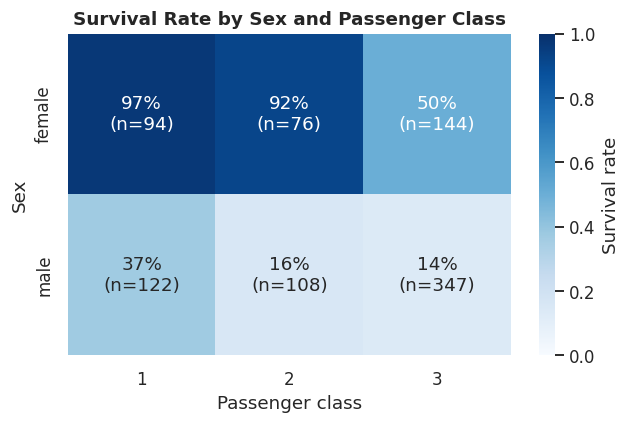

In [ ]:
# Survival rate for every combination of sex and class, with the group size in brackets
rate_table = eda.pivot_table(index="sex", columns="pclass", values=TARGET, aggfunc="mean")
size_table = eda.pivot_table(index="sex", columns="pclass", values=TARGET, aggfunc="size")
labels = rate_table.map(lambda v: f"{v:.0%}") + "\n(n=" + size_table.astype(str) + ")"

fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(rate_table, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "Survival rate"}, ax=ax)
ax.set_title("Survival Rate by Sex and Passenger Class")
ax.set_xlabel("Passenger class"); ax.set_ylabel("Sex")
plt.show()

**What this shows:** the bar charts compare raw counts; the heatmap compares *rates* for every sex-and-class combination, with the number of passengers in each cell. Rates are more fair than counts when groups have different sizes. Look for whether the sex pattern holds in every class, and whether the class pattern holds for both sexes.

### 4.3 Age: distribution and survival

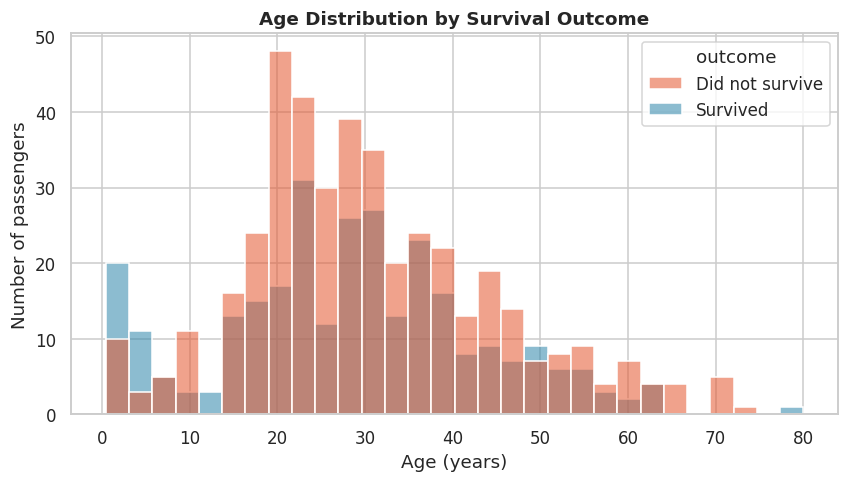

Passengers with a known age: 714 of 891


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=eda, x="age", hue="outcome", hue_order=list(OUTCOME_LABELS.values()),
             palette=OUTCOME_COLORS, bins=30, multiple="layer", alpha=0.55, ax=ax)
ax.set_title("Age Distribution by Survival Outcome")
ax.set_xlabel("Age (years)"); ax.set_ylabel("Number of passengers")
plt.show()
print(f"Passengers with a known age: {eda['age'].notna().sum()} of {len(eda)}")

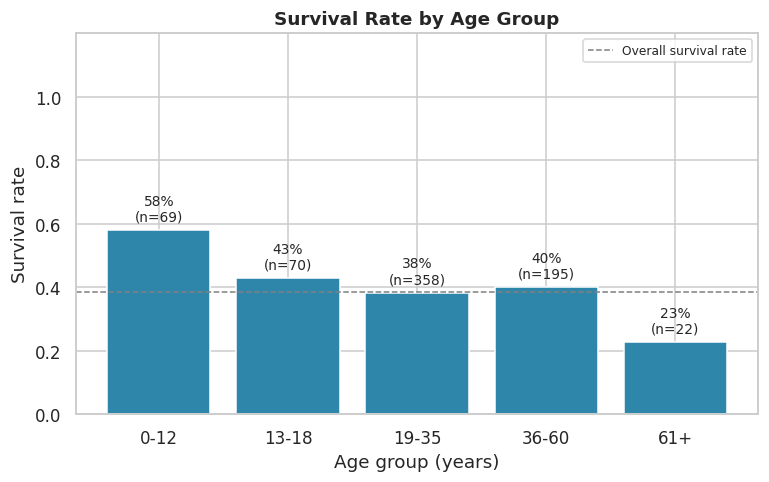

In [ ]:
age_bins = [0, 12, 18, 35, 60, 120]
age_labels = ["0-12", "13-18", "19-35", "36-60", "61+"]
eda["age_group"] = pd.cut(eda["age"], bins=age_bins, labels=age_labels, include_lowest=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
age_summary = plot_survival_rate(eda, "age_group", ax, "Survival Rate by Age Group", "Age group (years)", order=age_labels)
plt.show()

**What this shows:** the histogram compares *how many* passengers of each age did or did not survive. The second chart groups ages into bands and shows the survival *rate* with the group size.

**Caveat:** passengers with a missing age are left out of these two charts. Some age groups are small, so their rates are less stable than the large groups.

### 4.4 Fare: distribution and survival

Passengers with a fare of exactly 0: 15


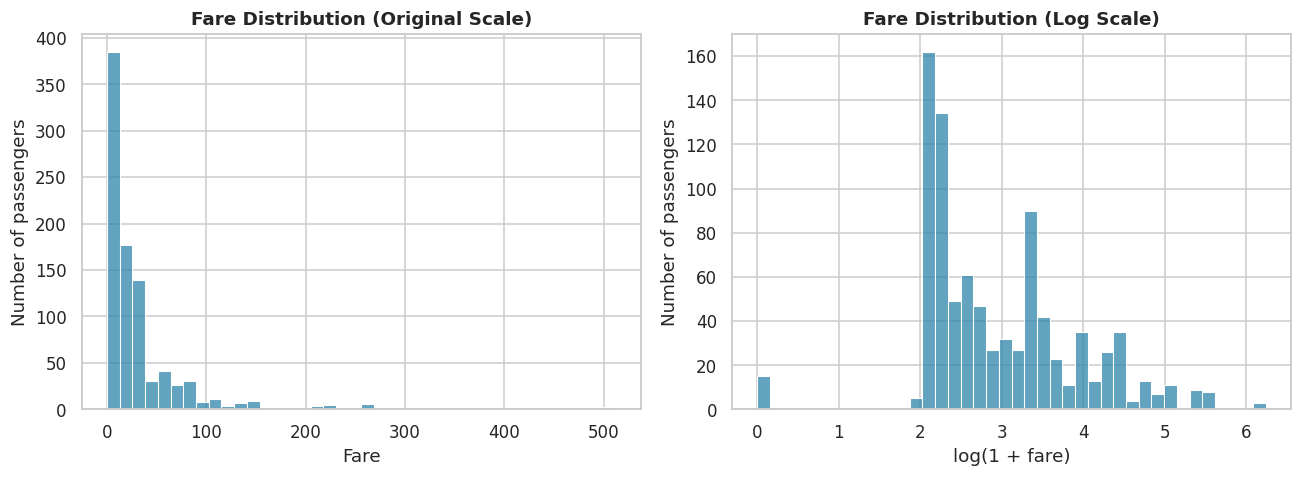

In [ ]:
print("Passengers with a fare of exactly 0:", int((eda["fare"] == 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(data=eda, x="fare", bins=40, color=BAR_COLOR, ax=axes[0])
axes[0].set_title("Fare Distribution (Original Scale)")
axes[0].set_xlabel("Fare"); axes[0].set_ylabel("Number of passengers")

# log1p(x) = log(1 + x). The "+1" keeps zero fares valid.
sns.histplot(x=np.log1p(eda["fare"]), bins=40, color=BAR_COLOR, ax=axes[1])
axes[1].set_title("Fare Distribution (Log Scale)")
axes[1].set_xlabel("log(1 + fare)"); axes[1].set_ylabel("Number of passengers")
plt.tight_layout()
plt.show()

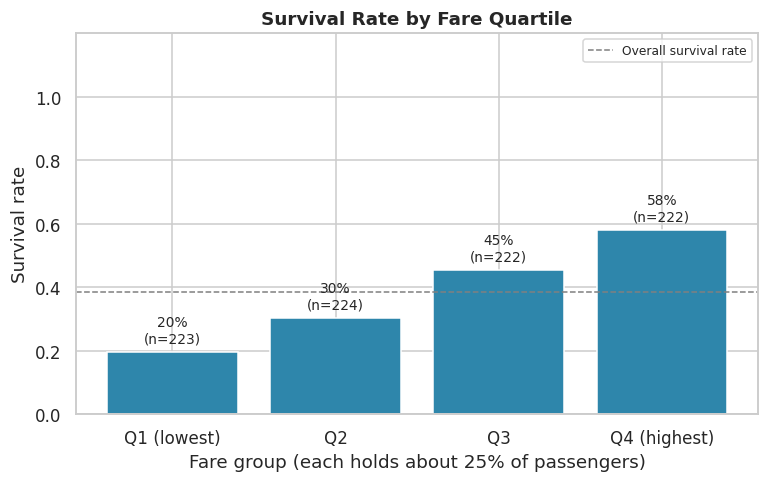

In [ ]:
eda["fare_quartile"] = pd.qcut(eda["fare"], q=4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

fig, ax = plt.subplots(figsize=(8, 4.5))
fare_summary = plot_survival_rate(eda, "fare_quartile", ax, "Survival Rate by Fare Quartile", "Fare group (each holds about 25% of passengers)")
plt.show()

**What this shows:** the original-scale histogram is squeezed to the left by a few very expensive fares. The log view spreads those values out, making the shape easier to read. This is also a hint that a few extreme fares exist, which is one reason we scale numeric features. The quartile chart compares survival rates from the cheapest to the most expensive fares.

**Caveat:** fare is strongly tied to passenger class, so these two features carry overlapping information.

### 4.5 Embarkation port

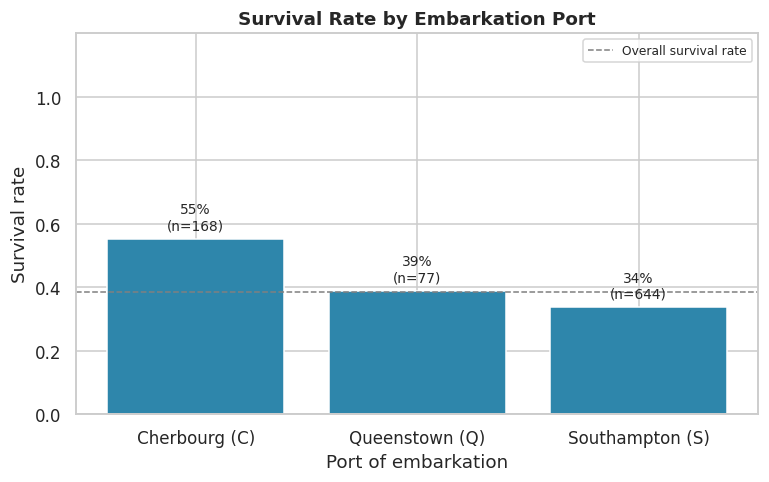

Passengers with a missing port (not shown): 2


In [ ]:
port_names = {"S": "Southampton (S)", "C": "Cherbourg (C)", "Q": "Queenstown (Q)"}
eda["embarked_port"] = eda["embarked"].map(port_names)

fig, ax = plt.subplots(figsize=(8, 4.5))
port_summary = plot_survival_rate(eda, "embarked_port", ax, "Survival Rate by Embarkation Port", "Port of embarkation")
plt.show()
print("Passengers with a missing port (not shown):", int(eda["embarked"].isna().sum()))

**What this shows:** the survival rate for each port, with the number of passengers in each group written on the bars. Ports with few passengers give less reliable rates.

**Caveat:** the port is probably not a *cause* of survival. Passengers who boarded at different ports differed in class and other traits, so this pattern may simply reflect those differences.

### 4.6 Family patterns: `sibsp` and `parch`

- `sibsp` = number of siblings or spouses aboard
- `parch` = number of parents or children aboard

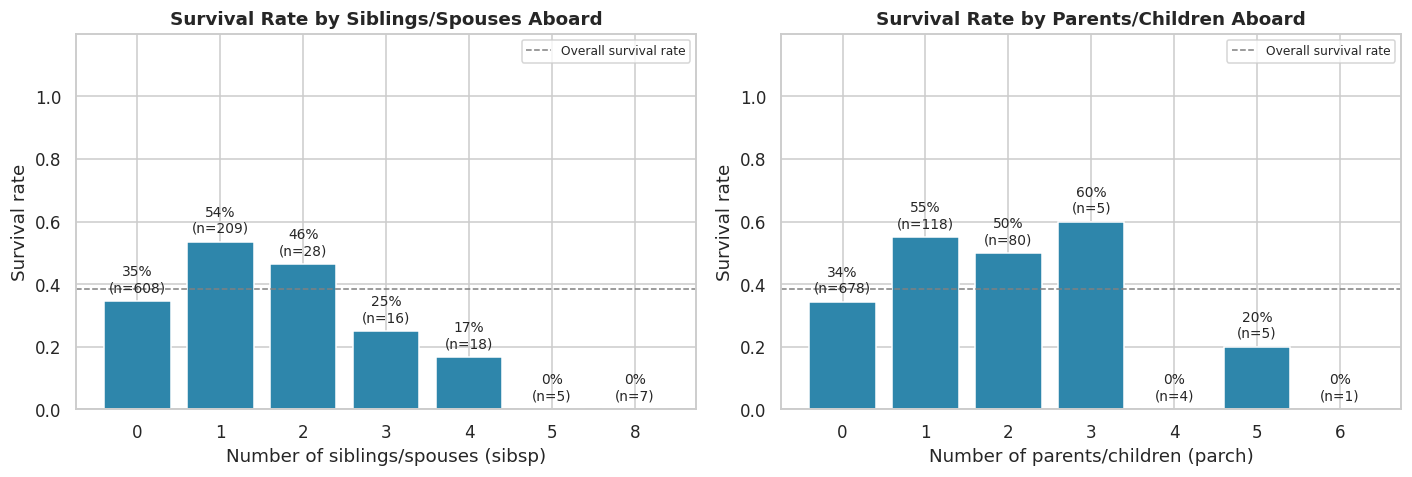

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_survival_rate(eda, "sibsp", axes[0], "Survival Rate by Siblings/Spouses Aboard", "Number of siblings/spouses (sibsp)")
plot_survival_rate(eda, "parch", axes[1], "Survival Rate by Parents/Children Aboard", "Number of parents/children (parch)")
plt.tight_layout()
plt.show()

**What this shows:** survival rate for each value of `sibsp` and `parch`. Large values are very rare, so those bars rest on only a handful of passengers; read them with care. In the feature engineering section we combine the two columns into one `family_size` feature.

### 4.7 Missing values

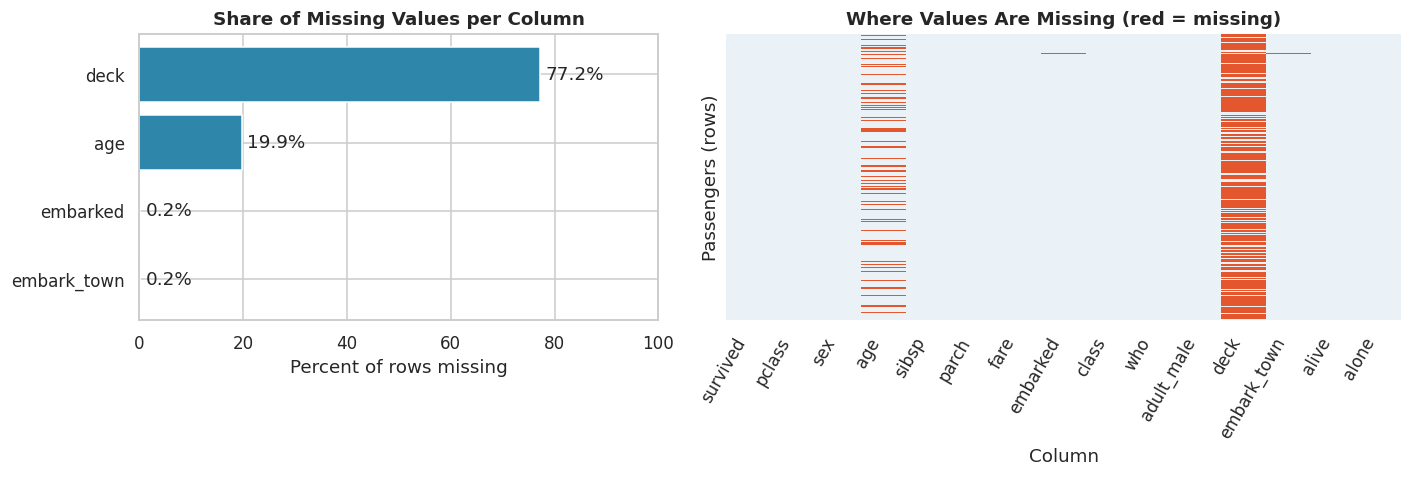

In [ ]:
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
missing_percent = missing_percent[missing_percent > 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})

axes[0].barh(missing_percent.index[::-1], missing_percent.values[::-1], color=BAR_COLOR)
for i, v in enumerate(missing_percent.values[::-1]):
    axes[0].text(v + 1, i, f"{v:.1f}%", va="center")
axes[0].set_xlim(0, 100)
axes[0].set_title("Share of Missing Values per Column")
axes[0].set_xlabel("Percent of rows missing")

sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap=["#EAF2F8", "#E4572E"], ax=axes[1])
axes[1].set_title("Where Values Are Missing (red = missing)")
axes[1].set_xlabel("Column"); axes[1].set_ylabel("Passengers (rows)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

**What this shows:** the left chart gives the share of missing values per column; the right chart shows which rows are missing. Missing values in `age` and `embarked` will be filled inside the pipeline. A column that is missing for most rows (see the chart) is a poor feature candidate.

### 4.8 Summary of main observations

These numbers are calculated from the data each time the notebook runs, so they stay correct if the CSV changes.

In [ ]:
rate_by = lambda col: eda.groupby(col, observed=True)[TARGET].mean()

sex_rates = rate_by("sex")
class_rates = rate_by("pclass")
age_rates = rate_by("age_group")
port_rates = rate_by("embarked_port")
fare_rates = rate_by("fare_quartile")

print(f"Overall survival rate: {overall_rate:.1%} ({int(eda[TARGET].sum())} of {len(eda)} passengers)")
print("\nBy sex:           ", ", ".join(f"{k}: {v:.0%}" for k, v in sex_rates.items()))
print("By passenger class:", ", ".join(f"class {k}: {v:.0%}" for k, v in class_rates.items()))
print("By age group:      ", ", ".join(f"{k}: {v:.0%}" for k, v in age_rates.items()))
print("By fare quartile:  ", ", ".join(f"{k}: {v:.0%}" for k, v in fare_rates.items()))
print("By port:           ", ", ".join(f"{k}: {v:.0%}" for k, v in port_rates.items()))
print(f"\nHighest-survival sex: {sex_rates.idxmax()}; highest-survival class: {class_rates.idxmax()}; "
      f"lowest-survival class: {class_rates.idxmin()}")

Overall survival rate: 38.4% (342 of 891 passengers)

By sex:            female: 74%, male: 19%
By passenger class: class 1: 63%, class 2: 47%, class 3: 24%
By age group:       0-12: 58%, 13-18: 43%, 19-35: 38%, 36-60: 40%, 61+: 23%
By fare quartile:   Q1 (lowest): 20%, Q2: 30%, Q3: 45%, Q4 (highest): 58%
By port:            Cherbourg (C): 55%, Queenstown (Q): 39%, Southampton (S): 34%

Highest-survival sex: female; highest-survival class: 1; lowest-survival class: 3


**How to read these observations (caveats):**

- These are **associations**, not causes. Sex, class, fare, and port are all tangled together (for example, fare tracks class), so a single feature's pattern can partly reflect another feature.
- Some groups are small, so their rates can swing a lot from small changes in who happens to be included.
- `age` is missing for a meaningful share of passengers, and those passengers may differ from the rest.
- This dataset is one historical record. It is not a random sample of all people in similar disasters.

## 5. Data leakage and feature selection

**Data leakage** happens when the model is given information that would not be available at prediction time, or that directly reveals the answer. It makes scores look great while the model learns nothing useful.

Let's examine every column that is not obviously a raw passenger measurement and test whether it duplicates or is derived from another column. These checks are calculated from the data, not assumed.

In [ ]:
# alive: text version of the target
alive_matches = (df["alive"].map({"yes": 1, "no": 0}) == df[TARGET]).mean()

# class: text version of pclass
class_matches = (df["class"].map({"First": 1, "Second": 2, "Third": 3}) == df["pclass"]).mean()

# embark_town: full name of the embarked code
town_to_code = {"Southampton": "S", "Cherbourg": "C", "Queenstown": "Q"}
town_matches = (df["embark_town"].map(town_to_code).fillna("missing") == df["embarked"].fillna("missing")).mean()

# who: man / woman / child, which looks derived from sex and age
child_max_age = df.loc[df["who"] == "child", "age"].max()
nonchild_min_age = df.loc[df["who"] != "child", "age"].min()

# adult_male: should agree with who == "man"
adult_male_matches = (df["adult_male"] == (df["who"] == "man")).mean()

# alone: should agree with having no siblings, spouse, parents, or children aboard
alone_matches = (df["alone"] == ((df["sibsp"] + df["parch"]) == 0)).mean()

deck_missing = df["deck"].isna().mean()

print(f"alive vs survived        -> identical in {alive_matches:.1%} of rows")
print(f"class vs pclass          -> same information in {class_matches:.1%} of rows")
print(f"embark_town vs embarked  -> same information in {town_matches:.1%} of rows")
print(f"who                      -> 'child' ages go up to {child_max_age}; non-child ages start at {nonchild_min_age} (derived from age and sex)")
print(f"adult_male vs who=='man' -> same in {adult_male_matches:.1%} of rows")
print(f"alone vs (sibsp+parch==0)-> same in {alone_matches:.1%} of rows")
print(f"deck                     -> missing in {deck_missing:.1%} of rows")

alive vs survived        -> identical in 100.0% of rows
class vs pclass          -> same information in 100.0% of rows
embark_town vs embarked  -> same information in 100.0% of rows
who                      -> 'child' ages go up to 15.0; non-child ages start at 16.0 (derived from age and sex)
adult_male vs who=='man' -> same in 100.0% of rows
alone vs (sibsp+parch==0)-> same in 100.0% of rows
deck                     -> missing in 77.2% of rows


In [ ]:
decisions = pd.DataFrame([
    ("survived",   "TARGET",   "The outcome we want to predict."),
    ("alive",      "EXCLUDED - leakage", "Text copy of the target ('yes'/'no'). Using it would give the model the answer."),
    ("class",      "EXCLUDED - redundant", "Text copy of pclass (First/Second/Third)."),
    ("embark_town","EXCLUDED - redundant", "Full name of the port; identical information to embarked."),
    ("who",        "EXCLUDED - derived", "man/woman/child, which appears to be built from sex and age (see the check above). We use the original sex and age."),
    ("adult_male", "EXCLUDED - derived", "True/False version of who == 'man'; therefore also derived from sex and age."),
    ("alone",      "EXCLUDED - redundant", "Equals 'no siblings, spouse, parents, or children aboard'. Fully determined by sibsp and parch (and by family_size, created below)."),
    ("deck",       "EXCLUDED - mostly missing", "Missing for most passengers, and the website does not collect it."),
    ("pclass",     "USED", "Ticket class (1, 2, 3). Treated as a category."),
    ("sex",        "USED", "Passenger sex."),
    ("age",        "USED", "Age in years (missing values are filled in the pipeline)."),
    ("sibsp / parch", "USED via family_size", "Combined into family_size in the next section."),
    ("fare",       "USED", "Ticket price paid."),
    ("embarked",   "USED", "Port code: S, C, or Q (missing values are filled in the pipeline)."),
], columns=["column", "decision", "reason"])

display(decisions.style.hide(axis="index").set_properties(**{"text-align": "left"}))

column,decision,reason
survived,TARGET,The outcome we want to predict.
alive,EXCLUDED - leakage,Text copy of the target ('yes'/'no'). Using it would give the model the answer.
class,EXCLUDED - redundant,Text copy of pclass (First/Second/Third).
embark_town,EXCLUDED - redundant,Full name of the port; identical information to embarked.
who,EXCLUDED - derived,"man/woman/child, which appears to be built from sex and age (see the check above). We use the original sex and age."
adult_male,EXCLUDED - derived,True/False version of who == 'man'; therefore also derived from sex and age.
alone,EXCLUDED - redundant,"Equals 'no siblings, spouse, parents, or children aboard'. Fully determined by sibsp and parch (and by family_size, created below)."
deck,EXCLUDED - mostly missing,"Missing for most passengers, and the website does not collect it."
pclass,USED,"Ticket class (1, 2, 3). Treated as a category."
sex,USED,Passenger sex.


**Why these decisions matter**

- `alive` is the only true **leakage** column: it is the target written as words.
- The other excluded columns are not leakage, but they are **redundant** (they repeat another column) or **derived** (calculated from other columns). Keeping them would add no new information and make the model harder to explain. For a simple linear model it would also make the coefficients unstable, because the same information would appear several times.
- Using the original `sex`, `age`, `pclass`, and `embarked` also matches the inputs the website asks for.

**Final model input columns:** `pclass`, `sex`, `age`, `family_size`, `fare`, `embarked` (where `family_size` is created next).

## 6. Feature engineering

**Feature engineering** means creating more useful input columns from existing ones. We can only use what the file contains, so we create:

- `family_size = sibsp + parch + 1` (the `+ 1` counts the passenger themselves)
- `is_alone` and `family_group`, **for analysis only**, to understand family patterns

In [ ]:
df["family_size"] = df["sibsp"] + df["parch"] + 1
df["is_alone"] = (df["family_size"] == 1).astype(int)
df["family_group"] = pd.cut(df["family_size"], bins=[0, 1, 4, 20], labels=["Alone (1)", "Small (2-4)", "Large (5+)"])

display(df[["sibsp", "parch", "family_size", "is_alone", "family_group"]].head())

,sibsp,parch,family_size,is_alone,family_group
0,1,0,2,0,Small (2-4)
1,1,0,2,0,Small (2-4)
2,0,0,1,1,Alone (1)
3,1,0,2,0,Small (2-4)
4,0,0,1,1,Alone (1)


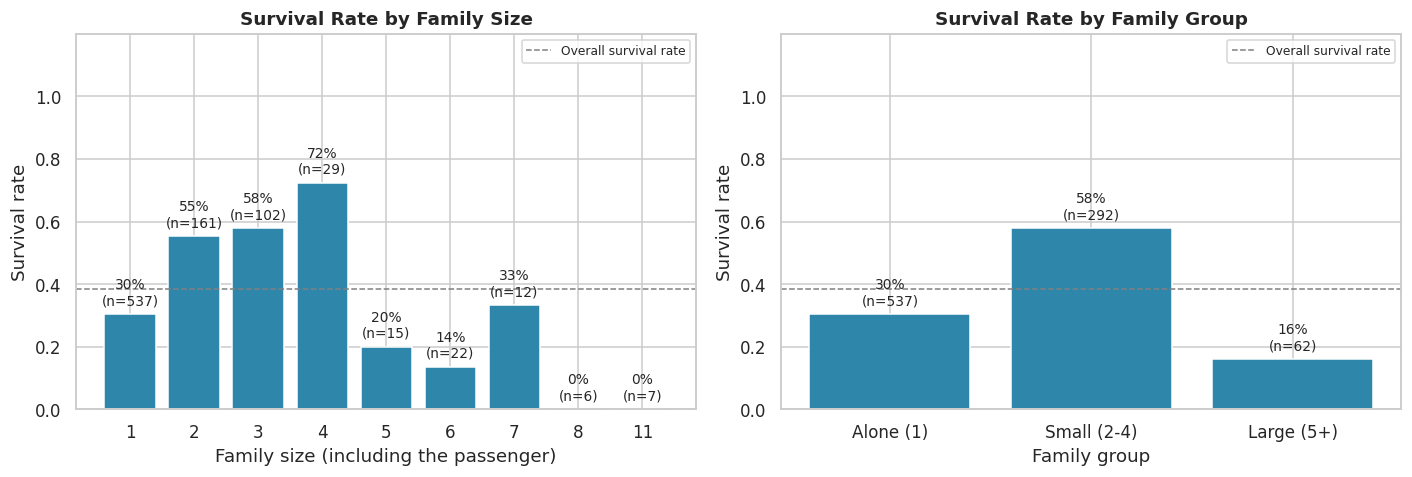

In [ ]:
eda["family_size"] = df["family_size"]
eda["family_group"] = df["family_group"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_survival_rate(eda, "family_size", axes[0], "Survival Rate by Family Size", "Family size (including the passenger)")
plot_survival_rate(eda, "family_group", axes[1], "Survival Rate by Family Group", "Family group")
plt.tight_layout()
plt.show()

**What this shows:** how survival changes as family size grows, and the same information in three simple groups. Very large families are rare, so their bars are based on few passengers.

### Redundancy: should `is_alone` and `family_group` go into the model?

`is_alone` is simply "`family_size` equals 1", and `family_group` is just `family_size` cut into ranges. They contain **no information that `family_size` does not already contain**. Adding them gives the model the same signal three times, which mostly adds clutter (and, for linear models, correlated inputs). So we **analyze** them here but **keep only `family_size`** in the model.

We will compare two feature sets fairly in the model comparison section:

| Feature set | Columns |
|---|---|
| **Baseline** | `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked` |
| **Engineered** | `pclass`, `sex`, `age`, `family_size`, `fare`, `embarked` |

In [ ]:
BASELINE_FEATURES = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
ENGINEERED_FEATURES = ["pclass", "sex", "age", "family_size", "fare", "embarked"]   # same as the website inputs

# Numeric vs categorical columns (pclass is a category: class 2 is not "twice" class 1)
NUMERIC_BASELINE, CATEGORICAL_BASELINE = ["age", "sibsp", "parch", "fare"], ["pclass", "sex", "embarked"]
NUMERIC_ENGINEERED, CATEGORICAL_ENGINEERED = ["age", "family_size", "fare"], ["pclass", "sex", "embarked"]

print("Baseline features:  ", BASELINE_FEATURES)
print("Engineered features:", ENGINEERED_FEATURES)

Baseline features:   ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
Engineered features: ['pclass', 'sex', 'age', 'family_size', 'fare', 'embarked']


## 7. Train/validation split and preprocessing

**Rule:** split first, then fit anything that *learns from data* (imputers, scalers, encoders) only on the training rows. If the validation rows influenced those steps, the validation score would be too optimistic. This is a form of leakage too.

We use a **stratified** split, which keeps the survived/not-survived proportions the same in both parts. 80% of the passengers are for training and 20% for validation.

In [ ]:
train_df, valid_df = train_test_split(
    df, test_size=0.20, stratify=df[TARGET], random_state=RANDOM_STATE
)
y_train, y_valid = train_df[TARGET], valid_df[TARGET]

print(f"Training rows:   {len(train_df)}")
print(f"Validation rows: {len(valid_df)}")
print(f"Survival rate - training:   {y_train.mean():.1%}")
print(f"Survival rate - validation: {y_valid.mean():.1%}")

Training rows:   712
Validation rows: 179
Survival rate - training:   38.3%
Survival rate - validation: 38.5%


### Preprocessing with `Pipeline` and `ColumnTransformer`

| Column type | Step 1 | Step 2 |
|---|---|---|
| Numeric (`age`, `fare`, `family_size`, ...) | Fill missing values with the **median** (robust to extreme values) | **Standardize** (mean 0, spread 1) so features share a scale |
| Categorical (`pclass`, `sex`, `embarked`) | Fill missing values with the **most frequent** category | **One-hot encode** (one 0/1 column per category) |

Putting preprocessing and the model together in one `Pipeline` means that whenever we call `fit`, the preprocessing is learned only from the data passed to `fit`. In cross-validation, this is re-done inside each fold automatically.

In [ ]:
def build_preprocessor(numeric_features, categorical_features):
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_steps, numeric_features),
        ("cat", categorical_steps, categorical_features),
    ])

def make_pipeline(model, numeric_features, categorical_features):
    return Pipeline([
        ("preprocess", build_preprocessor(numeric_features, categorical_features)),
        ("model", model),
    ])

### Proof that the validation data is not used to fit preprocessing

In [ ]:
demo_preprocessor = build_preprocessor(NUMERIC_ENGINEERED, CATEGORICAL_ENGINEERED)
demo_preprocessor.fit(train_df[ENGINEERED_FEATURES])       # fitted on TRAINING rows only

learned_age_median = demo_preprocessor.named_transformers_["num"]["impute"].statistics_[0]
print(f"Age median learned by the imputer:      {learned_age_median}")
print(f"Median age of the training rows:        {train_df['age'].median()}")
print(f"Median age of the validation rows:      {valid_df['age'].median()}  <- not used for fitting")
print(f"Median age of ALL rows (would leak):    {df['age'].median()}")

Age median learned by the imputer:      28.5
Median age of the training rows:        28.5
Median age of the validation rows:      27.0  <- not used for fitting
Median age of ALL rows (would leak):    28.0


The imputer's learned value matches the **training** median. The validation rows only get *transformed* using values learned from the training rows.

## 8. Baseline and model comparison

### 8.1 The metrics, in plain English

All metrics treat **"survived" (1)** as the positive class.

| Metric | Question it answers |
|---|---|
| **Accuracy** | Of all passengers, what share did the model classify correctly? |
| **Precision** | When the model says "survived", how often is it right? |
| **Recall** | Of the passengers who really survived, how many did the model find? |
| **F1** | A single score balancing precision and recall (their harmonic mean). |
| **ROC-AUC** | How well does the model *rank* survivors above non-survivors, regardless of the cut-off? 0.5 = random guessing, 1.0 = perfect. |

### 8.2 Models we compare

- **Dummy baseline:** always predicts the most common class. Any real model must beat it.
- **Logistic Regression:** a simple, explainable linear model.
- **Decision Tree:** a set of if/then rules; easy to picture but can overfit.
- **Random Forest:** many trees voting together; usually more robust.

### How we pick fairly

1. Use **5-fold stratified cross-validation on the training rows only** to compare options and tune settings.
2. Look at the **validation set once** at the end, as an honest check. We do not tune against it.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}

def cross_validated_scores(pipeline, X, y):
    results = cross_validate(pipeline, X, y, cv=cv, scoring=cv_scoring)
    return {name: results[f"test_{name}"].mean() for name in cv_scoring}

def default_models():
    return {
        "Dummy baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    }

### 8.3 Baseline features vs engineered features

We run the same models with the same cross-validation folds on both feature sets. (Only training rows are used.)

In [ ]:
feature_sets = {
    "Baseline (sibsp + parch)": (BASELINE_FEATURES, NUMERIC_BASELINE, CATEGORICAL_BASELINE),
    "Engineered (family_size)": (ENGINEERED_FEATURES, NUMERIC_ENGINEERED, CATEGORICAL_ENGINEERED),
}

rows = []
for set_name, (features, numeric, categorical) in feature_sets.items():
    for model_name, model in default_models().items():
        if model_name == "Dummy baseline":
            continue
        scores = cross_validated_scores(make_pipeline(model, numeric, categorical), train_df[features], y_train)
        rows.append({"Feature set": set_name, "Model": model_name, "CV F1": scores["f1"], "CV ROC-AUC": scores["roc_auc"]})

feature_set_results = pd.DataFrame(rows)
display(feature_set_results.pivot(index="Model", columns="Feature set", values=["CV F1", "CV ROC-AUC"]).round(3))

CV F1                           \
Feature set         Baseline (sibsp + parch) Engineered (family_size)   
Model                                                                   
Decision Tree                          0.730                    0.728   
Logistic Regression                    0.730                    0.729   
Random Forest                          0.733                    0.734   

                                  CV ROC-AUC                           
Feature set         Baseline (sibsp + parch) Engineered (family_size)  
Model                                                                  
Decision Tree                          0.854                    0.854  
Logistic Regression                    0.853                    0.854  
Random Forest                          0.863                    0.866

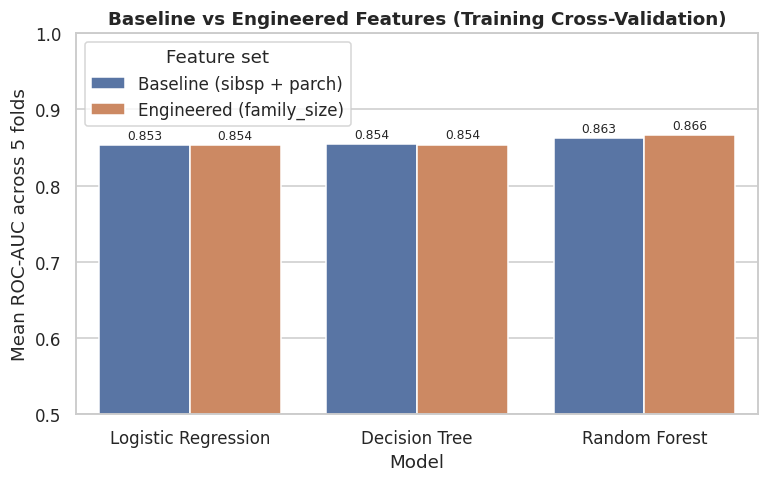

ROC-AUC change from using family_size instead of sibsp + parch:
Model
Decision Tree         -0.000
Logistic Regression    0.001
Random Forest          0.004


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=feature_set_results, x="Model", y="CV ROC-AUC", hue="Feature set", ax=ax)
ax.set_title("Baseline vs Engineered Features (Training Cross-Validation)")
ax.set_ylabel("Mean ROC-AUC across 5 folds")
ax.set_ylim(0.5, 1.0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)
plt.show()

pivot_auc = feature_set_results.pivot(index="Model", columns="Feature set", values="CV ROC-AUC")
diff = (pivot_auc["Engineered (family_size)"] - pivot_auc["Baseline (sibsp + parch)"]).round(3)
print("ROC-AUC change from using family_size instead of sibsp + parch:")
print(diff.to_string())

**How to read this:** if the two feature sets score about the same, `family_size` is a *simpler* way to describe the same information. It is also the input the website provides, so we use the engineered set for the rest of the project. Differences of only a few thousandths are within the normal noise of cross-validation and should not be over-interpreted.

### 8.4 Model comparison with cross-validation (default settings)

In [ ]:
cv_rows = []
for name, model in default_models().items():
    pipe = make_pipeline(model, NUMERIC_ENGINEERED, CATEGORICAL_ENGINEERED)
    cv_rows.append({"Model": name, **cross_validated_scores(pipe, train_df[ENGINEERED_FEATURES], y_train)})

cv_table = pd.DataFrame(cv_rows).set_index("Model").round(3)
cv_table.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
display(cv_table)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Dummy baseline,0.617,0.000,0.000,0.000,0.500
Logistic Regression,0.802,0.768,0.696,0.729,0.854
Decision Tree,0.815,0.833,0.652,0.728,0.854
Random Forest,0.798,0.743,0.729,0.734,0.866


The Dummy baseline shows what "no skill" looks like. Because it never predicts "survived", its precision, recall, and F1 are 0 and its ROC-AUC is 0.5, even though its accuracy is not zero. This is exactly why accuracy alone can mislead on imbalanced data.

### 8.5 Light tuning (training data only)

Each model's settings (hyperparameters) are tuned with `GridSearchCV`, which tries a small grid of values using cross-validation **inside the training set**. We optimize ROC-AUC. The validation set plays no part in this step.

In [ ]:
search_setup = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1, 10]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [2, 3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10, 20]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 3, 5, 10]},
    ),
}

X_train = train_df[ENGINEERED_FEATURES]
X_valid = valid_df[ENGINEERED_FEATURES]

fitted_models = {}      # name -> pipeline fitted on the training rows
tuning_rows = []

# The dummy baseline has nothing to tune
dummy_pipe = make_pipeline(DummyClassifier(strategy="most_frequent"), NUMERIC_ENGINEERED, CATEGORICAL_ENGINEERED)
fitted_models["Dummy baseline"] = dummy_pipe.fit(X_train, y_train)
tuning_rows.append({"Model": "Dummy baseline", "Best settings": "-", "CV ROC-AUC": cv_table.loc["Dummy baseline", "ROC-AUC"]})

for name, (model, grid) in search_setup.items():
    pipe = make_pipeline(model, NUMERIC_ENGINEERED, CATEGORICAL_ENGINEERED)
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    fitted_models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best settings": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        "CV ROC-AUC": round(search.best_score_, 3),
    })

tuning_table = pd.DataFrame(tuning_rows).set_index("Model")
display(tuning_table)

,Best settings,CV ROC-AUC
Model,,
Dummy baseline,-,0.500
Logistic Regression,{'C': 1},0.854
Decision Tree,"{'max_depth': 6, 'min_samples_leaf': 5}",0.855
Random Forest,"{'max_depth': None, 'min_samples_leaf': 3}",0.878


### 8.6 Final check on the validation set

Now each tuned model predicts the 20% of passengers it has never seen. Predictions use the standard cut-off: a predicted probability of at least 0.5 means "survived".

In [ ]:
def evaluate(pipeline, X, y):
    predictions = pipeline.predict(X)
    probabilities = pipeline.predict_proba(X)[:, 1]
    return {
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities),
    }

validation_table = pd.DataFrame({name: evaluate(p, X_valid, y_valid) for name, p in fitted_models.items()}).T
validation_table.insert(0, "CV ROC-AUC (train)", tuning_table["CV ROC-AUC"].astype(float))
display(validation_table.round(3).sort_values("ROC-AUC", ascending=False))

,CV ROC-AUC (train),Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.854,0.799,0.780,0.667,0.719,0.839
Random Forest,0.878,0.799,0.811,0.623,0.705,0.833
Decision Tree,0.855,0.765,0.765,0.565,0.650,0.785
Dummy baseline,0.500,0.615,0.000,0.000,0.000,0.500


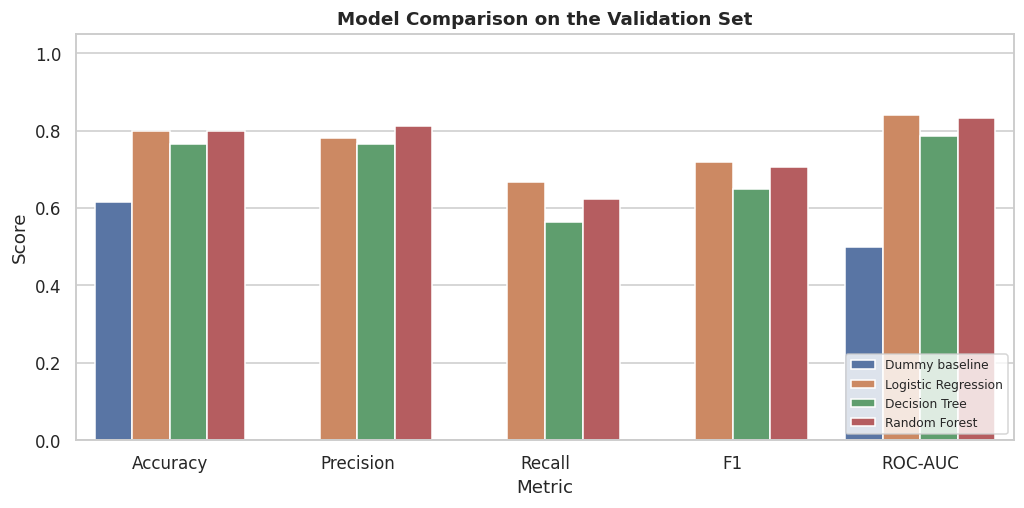

In [ ]:
plot_table = validation_table.drop(columns="CV ROC-AUC (train)").reset_index(names="Model").melt(
    id_vars="Model", var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.barplot(data=plot_table, x="Metric", y="Score", hue="Model", ax=ax)
ax.set_title("Model Comparison on the Validation Set")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.legend(loc="lower right", fontsize=8)
plt.show()

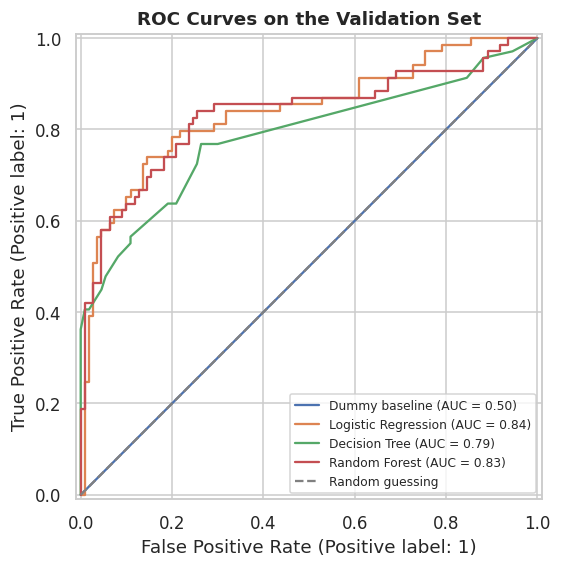

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, pipe in fitted_models.items():
    RocCurveDisplay.from_estimator(pipe, X_valid, y_valid, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing")
ax.set_title("ROC Curves on the Validation Set")
ax.legend(loc="lower right", fontsize=8)
plt.show()

**What these show:** the table and bar chart compare all five metrics. The ROC curve shows the trade-off between catching survivors and raising false alarms across every possible cut-off; the closer a curve hugs the top-left corner, the better.

### 8.7 Selecting the model

**Selection rule:** the model with the best **cross-validated ROC-AUC on the training data** is chosen. The validation scores then act as an independent confirmation. This avoids "shopping" for whichever model happens to look best on the validation rows. If the validation ranking disagrees, we note it, because small differences between good models are often just noise.

In [ ]:
candidates = tuning_table.drop(index="Dummy baseline")
selected_name = candidates["CV ROC-AUC"].astype(float).idxmax()
selected_model = fitted_models[selected_name]

validation_winner = validation_table.drop(index="Dummy baseline")["ROC-AUC"].idxmax()
print(f"Selected model (best training cross-validation ROC-AUC): {selected_name}")
print(f"Best ROC-AUC on the validation set:                       {validation_winner}")
if validation_winner == selected_name:
    print("-> The validation results agree with the cross-validation choice.")
else:
    gap = validation_table.loc[validation_winner, "ROC-AUC"] - validation_table.loc[selected_name, "ROC-AUC"]
    print(f"-> The validation ranking differs, by {gap:.3f} ROC-AUC. We keep the pre-planned rule rather than re-picking on the validation set.")

selected_scores = validation_table.loc[selected_name]
dummy_scores = validation_table.loc["Dummy baseline"]
print(f"\nValidation accuracy: {selected_scores['Accuracy']:.3f} (dummy baseline: {dummy_scores['Accuracy']:.3f})")
print(f"Validation ROC-AUC:  {selected_scores['ROC-AUC']:.3f} (dummy baseline: {dummy_scores['ROC-AUC']:.3f})")

Selected model (best training cross-validation ROC-AUC): Random Forest
Best ROC-AUC on the validation set:                       Logistic Regression
-> The validation ranking differs, by 0.006 ROC-AUC. We keep the pre-planned rule rather than re-picking on the validation set.

Validation accuracy: 0.799 (dummy baseline: 0.615)
Validation ROC-AUC:  0.833 (dummy baseline: 0.500)


**Why the cross-validation score of the tuned models is higher than their validation score:** we tried many settings and kept the best-scoring one, so its cross-validation score is slightly *optimistic* (we picked the winner of many tries). The validation set was never used for choosing anything, so it gives the more honest number. Also, with only 179 validation passengers, a single split is noisy, so small gaps between models are not meaningful.

### 8.8 Confusion matrix of the selected model

A **confusion matrix** counts correct and incorrect predictions:

- Top-left: correctly predicted *did not survive*
- Bottom-right: correctly predicted *survived*
- Top-right: predicted *survived* but did **not** (false alarms)
- Bottom-left: predicted *did not survive* but **did** survive (missed survivors)

The right-hand version shows percentages within each true outcome.

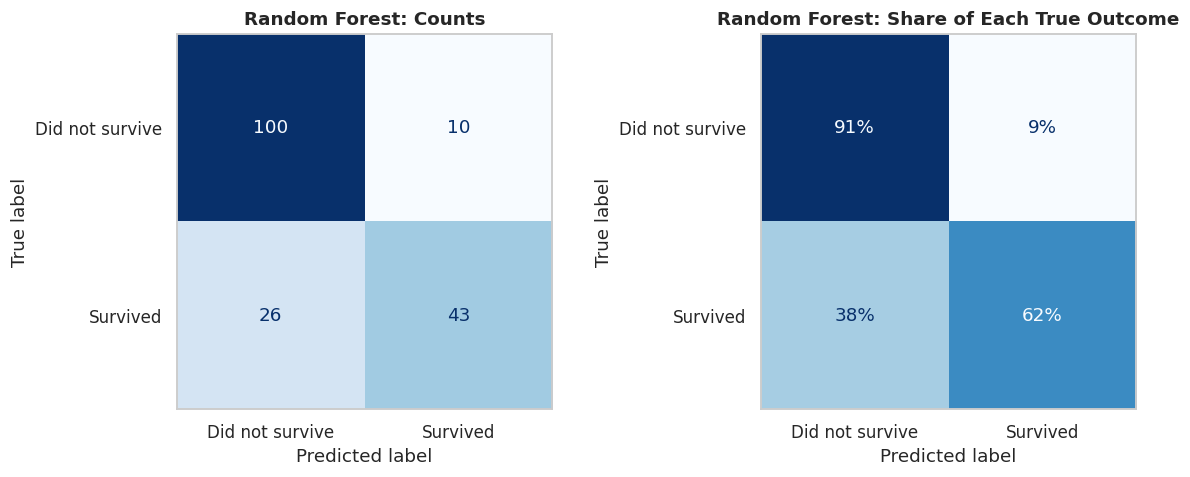

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
class_names = list(OUTCOME_LABELS.values())

ConfusionMatrixDisplay.from_estimator(selected_model, X_valid, y_valid, display_labels=class_names,
                                      cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"{selected_name}: Counts")

ConfusionMatrixDisplay.from_estimator(selected_model, X_valid, y_valid, display_labels=class_names,
                                      normalize="true", values_format=".0%", cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title(f"{selected_name}: Share of Each True Outcome")
for ax in axes:
    ax.grid(False)
plt.tight_layout()
plt.show()

## 9. Model interpretation

We want to know *which inputs the model relies on*. We use two complementary tools.

### 9.1 Permutation importance (works for any model)

**Idea:** shuffle one input column at random in the validation data and see how much the score drops. If shuffling a column hurts the score a lot, the model was relying on it. We shuffle the original columns (such as `sex`), not the one-hot pieces, so the result is easy to read.

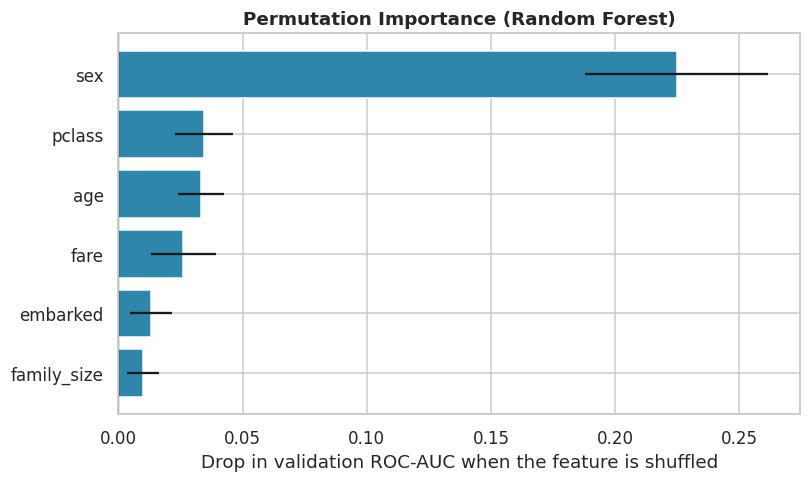

,feature,mean_drop,std
0,sex,0.2247,0.0368
1,pclass,0.0346,0.0117
2,age,0.0334,0.0093
3,fare,0.0262,0.0130
4,embarked,0.0130,0.0085
5,family_size,0.0099,0.0063


In [ ]:
perm = permutation_importance(
    selected_model, X_valid, y_valid,
    scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE,
)
importance = pd.DataFrame({
    "feature": ENGINEERED_FEATURES,
    "mean_drop": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("mean_drop")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance["feature"], importance["mean_drop"], xerr=importance["std"], color=BAR_COLOR)
ax.set_title(f"Permutation Importance ({selected_name})")
ax.set_xlabel("Drop in validation ROC-AUC when the feature is shuffled")
ax.axvline(0, color="black", linewidth=0.8)
plt.show()
display(importance.sort_values("mean_drop", ascending=False).round(4).reset_index(drop=True))

**How to read it:** a longer bar means the model leans on that feature more. A bar near zero means shuffling the feature barely changed the score. Error bars show variation across 30 shuffles.

### 9.2 Logistic Regression coefficients (the simplest model to explain)

Logistic Regression gives each input a **coefficient**. We also show the **odds ratio** (`exp(coefficient)`):

- Odds ratio **above 1**: the feature is associated with *higher* odds of survival, holding the other inputs fixed.
- Odds ratio **below 1**: associated with *lower* odds.
- Numeric features were standardized, so their odds ratio describes a change of **one standard deviation**. Category columns (like `sex_male`) compare that category with the others.

This view uses the tuned Logistic Regression from above, whether or not it was the selected model.

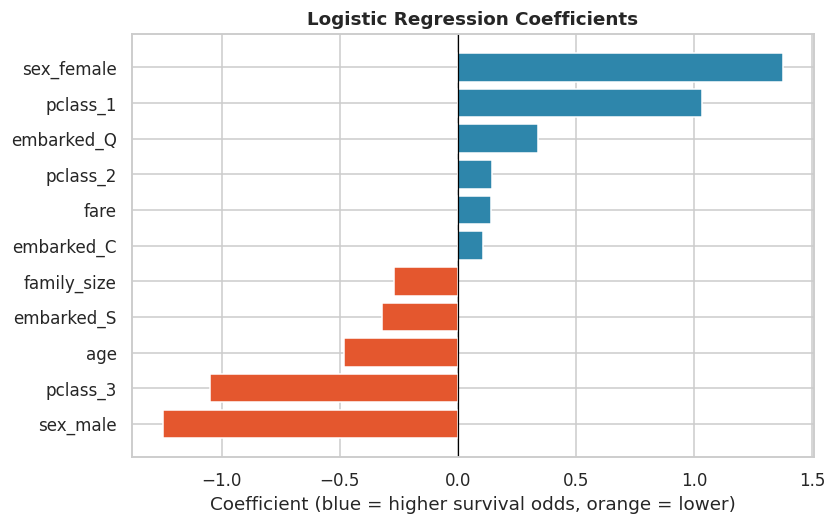

,feature,coefficient,odds_ratio
0,sex_female,1.374,3.950
1,pclass_1,1.031,2.803
2,embarked_Q,0.338,1.402
3,pclass_2,0.142,1.153
4,fare,0.140,1.150
5,embarked_C,0.106,1.112
6,family_size,-0.270,0.763
7,embarked_S,-0.321,0.725
8,age,-0.481,0.618
9,pclass_3,-1.050,0.350


In [ ]:
lr_pipeline = fitted_models["Logistic Regression"]
feature_names = lr_pipeline.named_steps["preprocess"].get_feature_names_out()
feature_names = [n.replace("num__", "").replace("cat__", "") for n in feature_names]

coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": lr_pipeline.named_steps["model"].coef_[0],
})
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])
coefficients = coefficients.sort_values("coefficient")

colors = [OUTCOME_COLORS["Survived"] if c > 0 else OUTCOME_COLORS["Did not survive"] for c in coefficients["coefficient"]]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coefficients["feature"], coefficients["coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression Coefficients")
ax.set_xlabel("Coefficient (blue = higher survival odds, orange = lower)")
plt.show()
display(coefficients.sort_values("coefficient", ascending=False).round(3).reset_index(drop=True))

### Association is not causation

- These results describe **patterns in historical data**, not reasons. A feature that is important to the model is *useful for prediction*, which is not the same as *causing* survival.
- Features overlap (fare and class, family size and age, and so on), so credit can be shared among them in ways that are not clean.
- **Feature importance describes the model, not individual people.** It cannot tell us why a specific real passenger lived or died. Many things that mattered on that night (where someone was, who helped them, luck) are not in this dataset.

## 10. Final model and example prediction

### 10.1 Two different models: one for the score, one for the demo

- The **validation score** above came from a model trained on 80% of the data and tested on the other 20%. It is our honest estimate of performance on unseen passengers.
- For an interactive demo it makes sense to use **all available rows** for the final fit, because more data gives a slightly better model. But once we fit on every row, we have **no unseen data left** to measure it, so we do **not** report a score for it. The honest estimate remains the validation score.

The final pipeline uses the same settings that were selected with cross-validation, and the exact input columns the website backend (`app.py`) expects: `pclass`, `sex`, `age`, `family_size`, `fare`, and `embarked`.

In [ ]:
WEBSITE_FEATURES = ["pclass", "sex", "age", "family_size", "fare", "embarked"]
assert WEBSITE_FEATURES == ENGINEERED_FEATURES, "Model inputs must match the website inputs"

# clone() copies the selected settings but starts untrained; we refit on ALL rows.
final_model = clone(selected_model).fit(df[WEBSITE_FEATURES], df[TARGET])
print("Final model:", selected_name)
print("Expected input columns:", WEBSITE_FEATURES)

Final model: Random Forest
Expected input columns: ['pclass', 'sex', 'age', 'family_size', 'fare', 'embarked']


### 10.2 Example passenger predictions

Each example is one row with the six input columns. The pipeline handles missing values, scaling, and encoding by itself, so we pass the raw values.

In [ ]:
example_passengers = pd.DataFrame([
    {"pclass": 1, "sex": "female", "age": 28, "family_size": 1, "fare": 80.0, "embarked": "C"},
    {"pclass": 3, "sex": "male",   "age": 30, "family_size": 1, "fare": 8.05, "embarked": "S"},
    {"pclass": 2, "sex": "male",   "age": 8,  "family_size": 4, "fare": 30.0, "embarked": "S"},
])

probabilities = final_model.predict_proba(example_passengers)[:, 1]
predictions = final_model.predict(example_passengers)

results = example_passengers.copy()
results["predicted_class"] = [OUTCOME_LABELS[p] for p in predictions]
results["survival_probability"] = (probabilities * 100).round(1).astype(str) + "%"
display(results)

,pclass,sex,age,family_size,fare,embarked,predicted_class,survival_probability
0,1,female,28,1,80.00,C,Survived,99.5%
1,3,male,30,1,8.05,S,Did not survive,14.3%
2,2,male,8,4,30.00,S,Survived,70.2%


**How to read this:** `survival_probability` is the model's *estimated chance* of survival for a passenger with those characteristics, based on the patterns in this dataset. `predicted_class` is simply "Survived" when that probability is at least 50%. Tree-based models such as Random Forest can sound more confident than they should (very high or very low percentages), because their probabilities are not calibrated; treat them as a rough ranking of likelihood, not as exact odds. These are **estimates from a historical pattern, not facts or guarantees** about any real person.

### 10.3 Saving the complete pipeline

We save the full pipeline (preprocessing **and** model) with `joblib`, so that the same cleaning steps are applied whenever it is loaded.

In [ ]:
MODEL_PATH = PROJECT_DIR / "titanic_survival_pipeline.joblib"
joblib.dump(final_model, MODEL_PATH)
print("Saved to:", MODEL_PATH)

# Verify: reload and confirm it gives the same answers
reloaded = joblib.load(MODEL_PATH)
same = np.allclose(reloaded.predict_proba(example_passengers), final_model.predict_proba(example_passengers))
print("Reloaded pipeline gives identical probabilities:", same)

Saved to: <project folder>/titanic_survival_pipeline.joblib
Re-running this cell saves the model beside Titanic.csv.


> **Connection:** `app.py` loads this saved pipeline from the project folder. If you retrain or change the final model, run the notebook's save cell again and restart the website. The pipeline accepts the same six input columns as the passenger form.

## 11. Conclusion and limitations

### Results at a glance (calculated from this run)

In [ ]:
top_features = importance.sort_values("mean_drop", ascending=False)["feature"].head(3).tolist()

print(f"Passengers analysed: {len(df)} | Overall survival rate: {overall_rate:.1%}")
print(f"Selected model: {selected_name} (best training cross-validation ROC-AUC = {tuning_table.loc[selected_name, 'CV ROC-AUC']})")
print(f"Validation accuracy: {selected_scores['Accuracy']:.3f} | F1: {selected_scores['F1']:.3f} | ROC-AUC: {selected_scores['ROC-AUC']:.3f}")
print(f"Dummy baseline on validation: accuracy {dummy_scores['Accuracy']:.3f} | F1: {dummy_scores['F1']:.3f} | ROC-AUC: {dummy_scores['ROC-AUC']:.3f}")
print(f"Features the selected model relied on most (permutation importance): {', '.join(top_features)}")
print(f"Saved pipeline: {MODEL_PATH.name}")

Passengers analysed: 891 | Overall survival rate: 38.4%
Selected model: Random Forest (best training cross-validation ROC-AUC = 0.878)
Validation accuracy: 0.799 | F1: 0.705 | ROC-AUC: 0.833
Dummy baseline on validation: accuracy 0.615 | F1: 0.000 | ROC-AUC: 0.500
Features the selected model relied on most (permutation importance): sex, pclass, age
Saved pipeline: titanic_survival_pipeline.joblib


### What we did

- Loaded and validated the data, removed the index column, and checked that all columns we used really exist.
- Explored survival patterns and noted caveats for each.
- Excluded the leaking column `alive` and several redundant or derived columns (`class`, `who`, `adult_male`, `alone`, `embark_town`, and the mostly-missing `deck`).
- Created `family_size` and compared the baseline and engineered feature sets.
- Split the data first, then built leak-free preprocessing pipelines.
- Compared a dummy baseline with Logistic Regression, Decision Tree, and Random Forest using cross-validation on the training data, then confirmed on a held-out validation set.
- Interpreted the model, saved a complete pipeline, and made example predictions.

### Limitations

- **One historical dataset.** Patterns here may not describe other events, and this file is a subset of the people who were aboard.
- **Estimates, not guarantees.** A predicted probability is a statistical estimate from past data. It says nothing certain about any real person.
- **Association, not causation.** Importance and coefficients show what is useful for prediction, not what caused survival.
- **Limited features.** There are no names, tickets, or cabins, and `age` has missing values we had to fill in. Real circumstances that mattered a great deal are not in the data.
- **Small data.** With under a thousand rows, validation scores can shift noticeably with a different split. Treat small score differences between models as noise.
- **Validation score vs the demo model.** The validation score comes from a model trained on 80% of the rows. The saved demo pipeline is fitted on *all* rows, so its score cannot be measured on unseen data. The validation score remains the honest estimate.

### Possible next steps

- Repeat the evaluation with several different random splits (or repeated cross-validation) to see how stable the results are.
- Try other models or feature ideas, and a broader tuning search.
- Check how the cut-off (currently 0.5) changes precision and recall.
- Retrain the saved pipeline after changing features or model settings, then restart the website so `app.py` loads the updated artifact.